### Data Preparation

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(url)

# Verify
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.isnull().sum().sort_values(ascending=False)[df.isnull().sum() > 0]

annual_income        369
industry             240
location             208
employment_status    194
lead_source          148
lead_score            35
dtype: int64

In [4]:
# Replacing missing values with 0 for 'annual_income' and 'lead_score',
#  and filling other missing values with 'NA'
df['annual_income']=df['annual_income'].fillna(0)
df['lead_score']=df['lead_score'].fillna(0)
df=df.fillna('NA')

In [5]:
# Checking that we effectively replaced missing values
df.isnull().sum().sort_values(ascending=False)[df.isnull().sum() > 0]

Series([], dtype: int64)

### Data Splitting

In [6]:
#
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

## Question 1: ROC AUC feature importance

In [24]:
from sklearn.metrics import roc_auc_score

numerical = [
    'lead_score',
    'number_of_courses_viewed',
    'interaction_count',
    'annual_income'
]


categorical= ['industry','employment_status','location',
              ]

In [8]:
y_train = df_train.converted.values
df_train = df_train.drop(columns=['converted'])

In [9]:
auc_scores = {}

for column in numerical:
    scores = df_train[column]
    auc = roc_auc_score(y_train, scores)

    if auc < 0.5:
        auc = roc_auc_score(y_train, -scores)

    auc_scores[column] = auc
    print(f'{column}: {auc:.4f}')

lead_score: 0.7882
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
annual_income: 0.6082


In [10]:
best_feature = max(auc_scores, key=auc_scores.get)
print(f'Best feature: {best_feature} with AUC: {auc_scores[best_feature]:.4f}')

Best feature: lead_score with AUC: 0.7882


## Question 2: Training the model

In [11]:
# remving 'converted' from the validation set
y_val = df_val.converted.values
df_val = df_val.drop(columns=['converted'])

In [12]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# converting the training data to a list of dictionaries
# orient='records' creates a list with one dictionary per row.
train_dicts = df_train.to_dict(orient='records')
# checking the first dictionary in the list
train_dicts[0]

{'lead_source': 'paid_ads',
 'industry': 'technology',
 'employment_status': 'employed',
 'location': 'asia',
 'annual_income': 80198.0,
 'number_of_courses_viewed': 5,
 'interaction_count': 9,
 'lead_score': 0.91}

In [13]:
# fit the DictVectorizer to the training data
dv = DictVectorizer(sparse=False) #store non zeroes

# fit_transform does two things:
# - Fit: learn which feature columns to create from the training dictionaries.
# - Transform: convert those dictionaries into a matrix using those columns.
X_train = dv.fit_transform(train_dicts)
# inspecting the shape of the resulting matrix
dv.get_feature_names_out()

array(['annual_income', 'employment_status=NA',
       'employment_status=employed', 'employment_status=self_employed',
       'employment_status=student', 'employment_status=unemployed',
       'industry=NA', 'industry=education', 'industry=finance',
       'industry=healthcare', 'industry=manufacturing', 'industry=retail',
       'industry=technology', 'interaction_count', 'lead_score',
       'lead_source=NA', 'lead_source=events',
       'lead_source=organic_search', 'lead_source=paid_ads',
       'lead_source=referral', 'lead_source=social_media', 'location=NA',
       'location=africa', 'location=asia', 'location=europe',
       'location=north_america', 'location=south_america',
       'number_of_courses_viewed'], dtype=object)

In [14]:
# train the logistic regression model
model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [15]:
# Reuse the training columns in the same order. 
# Fitting another vectorizer on validation could create different columns,
# making the model’s inputs inconsistent.A category appearing only in 
# validation is ignored by the vectorizer.
val_dicts = df_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)

In [16]:
# Probability predictions for each class
y_pred = model.predict_proba(X_val)[:, 1]

# Calculate the validation AUC
auc = roc_auc_score(y_val, y_pred)
print(f'Validation AUC: {auc:.3f}')

Validation AUC: 0.732


## Question 3: Precision and Recall

In [17]:
scores = []

thresholds = np.linspace(0, 1, num=101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

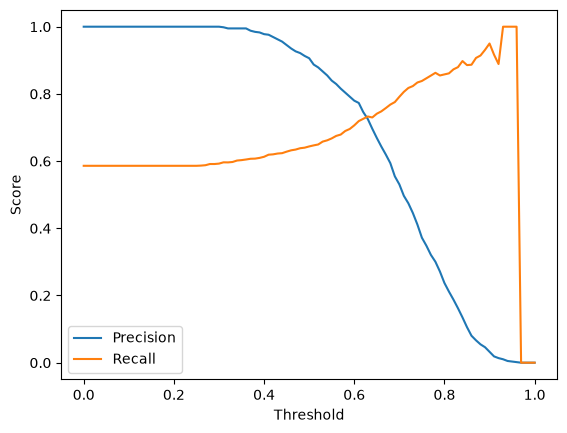

In [18]:
columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['precision'] = (df_scores.tp / (df_scores.tp + df_scores.fn).replace(0, np.nan)
).fillna(0)
df_scores['recall'] = (df_scores.tp / (df_scores.fp + df_scores.tp).replace(0, np.nan)
).fillna(0)
# Plotting the
plt.plot(df_scores.threshold, df_scores['precision'], label='Precision')
plt.plot(df_scores.threshold, df_scores['recall'], label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.show()

In [19]:
# Exclude thresholds where both metrics are zero
valid = df_scores[
    (df_scores.precision != 0) | (df_scores.recall != 0)
].copy()

valid['difference'] = abs(valid.precision - valid.recall)

best = valid.loc[valid.difference.idxmin()]

print(f"Threshold: {best['threshold']:.2f}")
print(f"Precision: {best['precision']:.3f}")
print(f"Recall: {best['recall']:.3f}")

Threshold: 0.63
Precision: 0.725
Recall: 0.733


## Question 4: F1 score

In [20]:
df_scores['F1'] = df_scores.precision * df_scores.recall * 2 / (df_scores.precision + df_scores.recall).replace(0, np.nan)
best_f1 = df_scores.loc[df_scores.F1.idxmax()]
print(f"Best F1 score: {best_f1['F1']:.3f} at threshold: {best_f1['threshold']:.2f}")

Best F1 score: 0.758 at threshold: 0.41


## Question 5: 5-Fold CV

In [22]:
from sklearn.model_selection import KFold
from tqdm.auto import tqdm

In [28]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [29]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [30]:
n_splits = 5

for C in tqdm([1]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/1 [00:00<?, ?it/s]

C=1 0.730 +- 0.007


## Question 6: Hyperparameter Tuning

In [31]:
n_splits = 5

for C in tqdm([0.000001, 0.001, 1]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 0.617 +- 0.019
C=0.001 0.746 +- 0.009
C=1 0.730 +- 0.007


We choose the C based on the highest mean AUC score and lowest standard deviation. In this case, C=1 seems to be the best choice with a mean AUC of 0.730 and a standard deviation of 0.007.